In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('dane/prognoza_ludnosci.csv', encoding='utf-8')

In [3]:
display(df.columns)

Index(['h3', 'dzielnica', 'pop_2025', 'pop_2026_niski', 'pop_2027_niski',
       'pop_2028_niski', 'pop_2029_niski', 'pop_2030_niski', 'pop_2031_niski',
       'pop_2032_niski', 'pop_2033_niski', 'pop_2034_niski', 'pop_2035_niski',
       'pop_2036_niski', 'pop_2026', 'pop_2027', 'pop_2028', 'pop_2029',
       'pop_2030', 'pop_2031', 'pop_2032', 'pop_2033', 'pop_2034', 'pop_2035',
       'pop_2036', 'pop_2026_wysoki', 'pop_2027_wysoki', 'pop_2028_wysoki',
       'pop_2029_wysoki', 'pop_2030_wysoki', 'pop_2031_wysoki',
       'pop_2032_wysoki', 'pop_2033_wysoki', 'pop_2034_wysoki',
       'pop_2035_wysoki', 'pop_2036_wysoki', 'pop_2036_wariant_gus',
       'mieszkania_w_budowie', 'dryf_roczny_proc', 'dP_2031', 'dP_2036',
       'dP_2031_norm', 'dP_2036_norm'],
      dtype='str')

In [6]:
wybrane = df.filter(regex=r"pop_20_niski", axis=1)

In [7]:
lata = range(2026, 2037)

# Przyrost względem poprzedniego roku: np. 2026 minus 2025
przyrost = pd.DataFrame(
    {
        f"dP_{rok}": df[f"pop_{rok}"] - df[f"pop_{rok - 1}"]
        for rok in lata
    },
    index=df.index,
)

min_w_roku = przyrost.min()
zakres_w_roku = przyrost.max() - min_w_roku

# Gdy wszystkie wartości w danym roku są równe, wynikiem będzie 0
przyrost_norm = przyrost.sub(min_w_roku).div(
    zakres_w_roku.where(zakres_w_roku != 0, 1)
)

przyrost_norm = przyrost_norm.rename(
    columns=lambda kolumna: f"{kolumna}_norm"
)
df[przyrost_norm.columns] = przyrost_norm

In [9]:
df['dP_2028_norm'].head(5)

0    0.156588
1    0.157861
2    0.155952
3    0.154042
4    0.157225
Name: dP_2028_norm, dtype: float64

In [ ]:
kolumny_norm = sorted(
    df.filter(regex=r"^dP_20\d{2}_norm$").columns,
    key=lambda kol: int(kol.split("_")[1])
)

# Skumulowany wynik po każdym kolejnym roku, osobno dla każdego h3
wynik = df[["h3"]].join(
    df[kolumny_norm]
      .sum(axis=1)
      .rename(columns=lambda kol: kol.replace("dP_", "skumulowany_dP_"))
)

display(wynik.head())

,h3,skumulowany_dP_2026_norm,skumulowany_dP_2027_norm,skumulowany_dP_2028_norm,skumulowany_dP_2029_norm,skumulowany_dP_2030_norm,skumulowany_dP_2031_norm,skumulowany_dP_2032_norm,skumulowany_dP_2033_norm,skumulowany_dP_2034_norm,skumulowany_dP_2035_norm,skumulowany_dP_2036_norm
0,881f53d9ebfffff,0.121040,0.230834,0.387422,0.497719,0.702383,0.881338,1.073096,1.279547,1.500875,1.738238,1.993328
1,881f53d9e3fffff,0.121513,0.232185,0.390046,0.501259,0.706786,0.886509,1.079949,1.288244,1.510578,1.749040,2.005327
2,881f53d9ddfffff,0.120095,0.229888,0.385840,0.495680,0.699479,0.876899,1.068656,1.274186,1.494508,1.729673,1.983565
3,881f53d9d7fffff,0.119149,0.227625,0.381667,0.490591,0.691800,0.867684,1.056918,1.259683,1.476987,1.711053,1.961353
4,881f53d9d5fffff,0.121513,0.232624,0.389849,0.501519,0.707046,0.887538,1.080977,1.289272,1.511606,1.751167,2.007454


In [16]:
df["wynik_skomulowany"] = df[kolumny_norm].sum(axis=1)

<Axes: title={'center': 'Rozkład skumulowanego przyrostu ludności w latach 2026-2036'}, ylabel='Skumulowany przyrost ludności'>

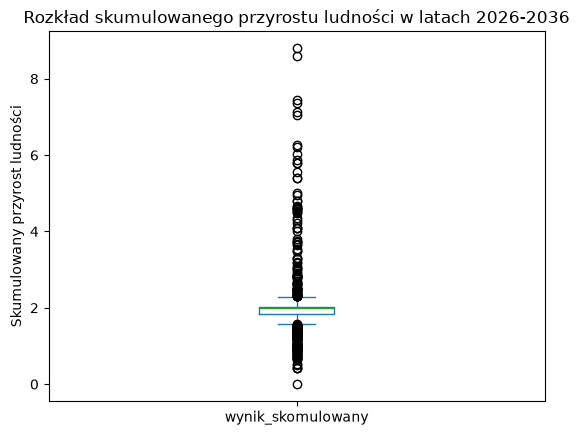

In [18]:
df['wynik_skomulowany'].plot(kind='box', title='Rozkład skumulowanego przyrostu ludności w latach 2026-2036', ylabel='Skumulowany przyrost ludności', xlabel='')